# Pronóstico global usando Prophet e incluyendo regresores tipo_dia y novedad como variables externas

In [219]:
import sys 
import os
from pathlib import Path
import importlib
from prefect import task
from pathlib import Path
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from prophet import Prophet
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from itertools import product

ROOT = Path().cwd().parents[1]
sys.path.append(str(ROOT))


import config.settings as settings
import importlib

import warnings
warnings.filterwarnings("ignore")

## Extraer la produccion por equipos

In [220]:
df_produccion = pd.read_excel(ROOT / 'data' / 'raw' / 'SESIONES_RADIOTERAPIA_5MAY22-30ABR2026.xlsx',
                                      sheet_name = 0,
                                      engine = "openpyxl")
df_produccion.columns = df_produccion.columns.str.lower()

In [221]:
print(df_produccion.columns)

Index(['fecha', 'equipo', 'produccion', 'capacidad', 'tipo_dia', 'novedad'], dtype='object')


In [222]:
df_produccion.columns = ["ds","equipo", "y", "capacidad", "tipo_dia", "novedad"]
print(df_produccion.head(3))

          ds    equipo   y  capacidad tipo_dia novedad
0 2022-05-03   HALCYON  59         70  laboral     NaN
1 2022-05-03   SYNERGY  41         65  laboral     NaN
2 2022-05-03  SYNERGY2  32         47  laboral     NaN


In [223]:
print(df_produccion.columns)

Index(['ds', 'equipo', 'y', 'capacidad', 'tipo_dia', 'novedad'], dtype='object')


In [224]:
df_produccion["ds"] = pd.to_datetime(df_produccion["ds"])

# Total servicios por dia

In [225]:
df_hist = df_produccion.copy()
demanda_diaria = df_produccion[["ds","y","capacidad","tipo_dia","novedad"]].groupby(['ds'], as_index = False).agg(
    tipo_dia = ("tipo_dia", "first"),
    novedad = ("novedad", "first"),
    y = ("y", "sum"),
    capacidad = ("capacidad", "sum"),
)
print(demanda_diaria)
print(df_hist.columns)

             ds       tipo_dia novedad    y  capacidad
0    2022-05-03        laboral    None  166        229
1    2022-05-04        laboral    None  180        229
2    2022-05-05        laboral    None  187        229
3    2022-05-06        laboral    None  140        229
4    2022-05-07  fin de semana    None    0          0
...         ...            ...     ...  ...        ...
1454 2026-04-26  fin de semana    None    0          0
1455 2026-04-27        laboral    None  200        307
1456 2026-04-28        laboral    None  209        307
1457 2026-04-29        laboral    None  197        307
1458 2026-04-30        festivo    None    0          0

[1459 rows x 5 columns]
Index(['ds', 'equipo', 'y', 'capacidad', 'tipo_dia', 'novedad'], dtype='object')


In [226]:
demanda_diaria = pd.get_dummies(demanda_diaria, columns = ["tipo_dia"])
demanda_diaria = pd.get_dummies(demanda_diaria, columns = ["novedad"])
df_hist = pd.get_dummies(df_hist, columns = ["tipo_dia"])
df_hist = pd.get_dummies(df_hist, columns = ["novedad"])
print(df_hist.columns)

Index(['ds', 'equipo', 'y', 'capacidad', 'tipo_dia_festivo',
       'tipo_dia_fin de semana', 'tipo_dia_laboral',
       'novedad_Control de Calidad', 'novedad_Falla', 'novedad_Mantenimiento'],
      dtype='object')


In [227]:
demanda_diaria.columns = ["ds", "y", "capacidad", "festivo", "fin_de_semana", "laboral", "control_calidad", "falla", "mantenimiento" ]
df_hist.columns = ["ds","equipo","y","capacidad", "festivo", "fin_de_semana", "laboral", "control_calidad", "falla", "mantenimiento"]

In [228]:
print(demanda_diaria.head(5))
print(df_hist.columns)


          ds    y  capacidad  festivo  fin_de_semana  laboral  \
0 2022-05-03  166        229    False          False     True   
1 2022-05-04  180        229    False          False     True   
2 2022-05-05  187        229    False          False     True   
3 2022-05-06  140        229    False          False     True   
4 2022-05-07    0          0    False           True    False   

   control_calidad  falla  mantenimiento  
0            False  False          False  
1            False  False          False  
2            False  False          False  
3            False  False          False  
4            False  False          False  
Index(['ds', 'equipo', 'y', 'capacidad', 'festivo', 'fin_de_semana', 'laboral',
       'control_calidad', 'falla', 'mantenimiento'],
      dtype='object')


In [229]:
demanda_diaria["ds"] = pd.to_datetime(demanda_diaria["ds"])
demanda_diaria = demanda_diaria.sort_values("ds")

demanda_diaria["media_30"] = (
    demanda_diaria["y"].rolling(window = 30, center= True).mean()
    )

demanda_diaria["media_90"] = (
    demanda_diaria["y"].rolling(window = 90, center = True).mean()
)

print(demanda_diaria.columns)

Index(['ds', 'y', 'capacidad', 'festivo', 'fin_de_semana', 'laboral',
       'control_calidad', 'falla', 'mantenimiento', 'media_30', 'media_90'],
      dtype='object')


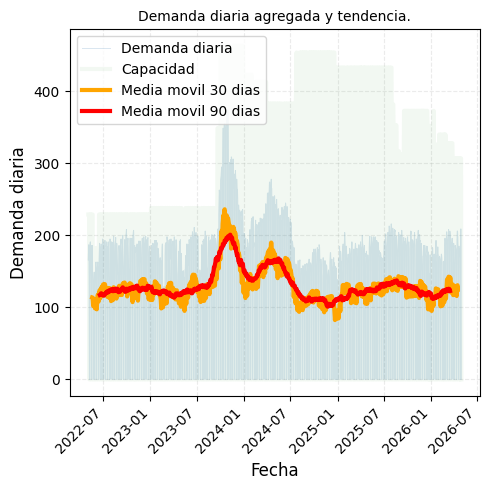

In [230]:
plt.figure(figsize = (5, 5))

plt.plot(
    demanda_diaria["ds"], 
    demanda_diaria["y"], 
    color = "steelblue",
    linewidth = 0.7, 
    alpha = 0.20, 
    label = "Demanda diaria"
)

plt.plot(
    demanda_diaria["ds"],
    demanda_diaria["capacidad"],
    color = "green",
    linewidth = 3,
    alpha = 0.05,
    label = "Capacidad"
)

plt.plot(
    demanda_diaria["ds"],
    demanda_diaria["media_30"],
    color = "orange",
    linewidth = 3,
    label = "Media movil 30 dias"
)

plt.plot(
    demanda_diaria["ds"],
    demanda_diaria["media_90"],
    color = "red",
    linewidth = 3,
    label = "Media movil 90 dias"
)

plt.title("Demanda diaria agregada y tendencia.", fontsize = 10)
plt.xlabel("Fecha",fontsize = 12)
plt.ylabel("Demanda diaria", fontsize = 12)

plt.xticks(rotation = 45, ha="right")

plt.grid(
    True,
    linestyle="--",
    alpha = 0.25
)

plt.legend(frameon = True)
plt.tight_layout()
plt.show()

## Dividir el dataset en subsets para entrenamiento, validacion, y test

In [231]:
print(demanda_diaria.columns)


Index(['ds', 'y', 'capacidad', 'festivo', 'fin_de_semana', 'laboral',
       'control_calidad', 'falla', 'mantenimiento', 'media_30', 'media_90'],
      dtype='object')


In [232]:
dates = demanda_diaria["ds"].sort_values().unique()
train_end = len(dates)-60
validation_end = len(dates)-30

In [233]:
train_dates = dates[:train_end]
validation_dates = dates[train_end:validation_end]
test_dates = dates[validation_end:]

In [234]:
train = demanda_diaria[demanda_diaria["ds"].isin(train_dates)] [["ds","y","capacidad","festivo","fin_de_semana","laboral","control_calidad", "falla", "mantenimiento"]]
validation = demanda_diaria[demanda_diaria["ds"].isin(validation_dates)] [["ds","y","capacidad","festivo","fin_de_semana","laboral","control_calidad", "falla", "mantenimiento"]]
test = demanda_diaria[demanda_diaria["ds"].isin(test_dates)] [["ds","y","capacidad","festivo","fin_de_semana","laboral", "control_calidad", "falla", "mantenimiento"]]

In [235]:
print(f"rows in train subset: {train.shape[0]}")
print(f"rows in validation subset: {validation.shape[0]}")
print(f"rows in test subset: {test.shape[0]}")


rows in train subset: 1399
rows in validation subset: 30
rows in test subset: 30


In [236]:
# Initialize and fit Prophet model
regressors = [c for c in train.columns if c not in ["ds","y","capacidad"]]
param_grid = {
    "changepoint_prior_scale": [0.01, 0.1, 0.5],
    "seasonality_prior_scale": [1,5,10]
}

train_total = train.groupby("ds")["y"].sum().reset_index()
validation_total = validation.groupby("ds")["y"].sum().reset_index()
train_regressors = train.groupby("ds")[regressors].mean().reset_index()
validation_regressors = validation.groupby("ds")[regressors].mean().reset_index()
train_total = train_total.merge(train_regressors, on = "ds")
validation_total = validation_total.merge(validation_regressors, on = "ds")
print(train_total.shape[0])
print(validation_total.shape[0])

1399
30


## Ajustar y tunear el modelo buscando los parametros que brinden un mejor ajuste a la serie global

In [237]:
best_params = None
best_rmse = np.inf

In [238]:
for cps,sps in product(
    param_grid["changepoint_prior_scale"], 
    param_grid["seasonality_prior_scale"]
):
    params = {
        "changepoint_prior_scale":cps,
        "seasonality_prior_scale":sps,
    }

    m = Prophet(
        weekly_seasonality = True,
        **params
    )

    for r in regressors:
        m.add_regressor(r)

    m.fit(train_total)

    forecast = m.predict(validation_total)

    pred = forecast["yhat"].values
    rmse = np.sqrt(mean_squared_error(validation_total["y"], pred))

    if rmse < best_rmse:
        best_rmse = rmse
        best_params = params

    
    

14:40:15.158 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

14:40:15.643 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

14:40:16.182 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

14:40:16.725 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

14:40:17.509 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

14:40:18.522 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

14:40:19.461 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

14:40:21.399 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

14:40:23.304 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

In [239]:
print(best_params)

{'changepoint_prior_scale': 0.1, 'seasonality_prior_scale': 5}


## Crear el modelo global

In [240]:
m_global = Prophet(weekly_seasonality = True, **best_params)
m_global.add_seasonality(name = "monthly", period = 30.5, fourier_order = 5)

## Entrenar el modelo global incluyendo los regresores

In [241]:
for r in regressors:
    m_global.add_regressor(r)
m_global.fit(train_total)

14:40:25.432 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

## Apilar los subconjuntos entrenamiento y validacion para evaluación de desempeno

In [242]:
train_full = demanda_diaria[demanda_diaria["ds"].isin(np.concatenate([train_dates, validation_dates]))] [["ds","y","capacidad","festivo","fin_de_semana","laboral","control_calidad", "falla", "mantenimiento"]]

In [243]:
pred_train_full = m_global.predict(train_full)
print(len(pred_train_full))
print(pred_train_full.head(5))

1429
          ds      trend  yhat_lower  yhat_upper  trend_lower  trend_upper  \
0 2022-05-03  78.899818  153.403655  208.138223    78.899818    78.899818   
1 2022-05-04  78.949128  154.293632  211.124463    78.949128    78.949128   
2 2022-05-05  78.998437  152.823437  209.972885    78.998437    78.998437   
3 2022-05-06  79.047747  146.478461  200.245609    79.047747    79.047747   
4 2022-05-07  79.097056  -46.739403    7.075745    79.097056    79.097056   

   additive_terms  additive_terms_lower  additive_terms_upper  \
0      101.644100            101.644100            101.644100   
1      103.764889            103.764889            103.764889   
2      102.367678            102.367678            102.367678   
3       94.765941             94.765941             94.765941   
4      -98.198155            -98.198155            -98.198155   

   control_calidad  ...     weekly  weekly_lower  weekly_upper    yearly  \
0              0.0  ...  20.236919     20.236919     20.236919 -0

In [244]:
train_compare = train_full.merge(pred_train_full[["ds","yhat"]],
                               on = "ds",
                               how = "inner")
train_compare["yhat"] = train_compare["yhat"].clip(lower = 0)
train_compare["se"] =  (train_compare['y'] - train_compare['yhat'])**2
totaly = np.sum(np.abs(train_compare["y"]))
print(totaly)
train_compare["wmape"] = np.abs(train_compare['y'] - train_compare['yhat'])
print(f"WMAPE = { 100 * np.sum(train_compare['wmape']) / totaly }")
print(f"Accuracy = {100-(100* train_compare['wmape'].sum()/totaly)}")
print(train_compare.head(5))
print(train_compare.shape[0])

186077
WMAPE = 10.225510703373024
Accuracy = 89.77448929662698
          ds    y  capacidad  festivo  fin_de_semana  laboral  \
0 2022-05-03  166        229    False          False     True   
1 2022-05-04  180        229    False          False     True   
2 2022-05-05  187        229    False          False     True   
3 2022-05-06  140        229    False          False     True   
4 2022-05-07    0          0    False           True    False   

   control_calidad  falla  mantenimiento        yhat           se      wmape  
0            False  False          False  180.543918   211.525544  14.543918  
1            False  False          False  182.714016     7.365885   2.714016  
2            False  False          False  181.366116    31.740654   5.633884  
3            False  False          False  173.813688  1143.365474  33.813688  
4            False  False          False    0.000000     0.000000   0.000000  
1429


## Pronóstico del test de datos

In [245]:
pred_test = m_global.predict(test)
print(len(pred_test))
print(pred_test.head(5))

30
          ds      trend  yhat_lower  yhat_upper  trend_lower  trend_upper  \
0 2026-04-01  95.760890  173.050817  229.054446    95.760890    95.760890   
1 2026-04-02  95.768006  171.256965  229.256932    95.768006    95.768006   
2 2026-04-03  95.775121  -28.760319   28.349000    95.775121    95.775121   
3 2026-04-04  95.782236  -23.980996   30.151290    95.782236    95.782236   
4 2026-04-05  95.789351  -22.058050   32.680595    95.789351    95.789351   

   additive_terms  additive_terms_lower  additive_terms_upper  \
0      106.633812            106.633812            106.633812   
1      105.292671            105.292671            105.292671   
2      -96.275257            -96.275257            -96.275257   
3      -92.092140            -92.092140            -92.092140   
4      -90.560881            -90.560881            -90.560881   

   control_calidad  ...     weekly  weekly_lower  weekly_upper    yearly  \
0              0.0  ...  21.448753     21.448753     21.448753  2.9

In [246]:
test_compare = test.merge(pred_test[["ds","yhat"]],
                               on = "ds",
                               how = "inner")
test_compare["yhat"] = test_compare["yhat"].clip(lower = 0)
test_compare["se"] =  (test_compare['y'] - test_compare['yhat'])**2
totaly = np.sum(np.abs(test_compare["y"]))
print(totaly)
test_compare["wmape"] = np.abs(test_compare['y'] - test_compare['yhat'])
print(f"WMAPE = { 100 * np.sum(test_compare['wmape']) / totaly }")
print(f"Accuracy = {100-(100* test_compare['wmape'].sum()/totaly)}")
print(test_compare.head(5))
print(test_compare.shape[0])


3735
WMAPE = 7.9190209164948095
Accuracy = 92.08097908350518
          ds    y  capacidad  festivo  fin_de_semana  laboral  \
0 2026-04-01  183        307    False          False     True   
1 2026-04-02  161        307    False          False     True   
2 2026-04-03    0          0     True          False    False   
3 2026-04-04    0          0    False           True    False   
4 2026-04-05    0          0    False           True    False   

   control_calidad  falla  mantenimiento        yhat           se      wmape  
0            False  False          False  202.394702   376.154475  19.394702  
1            False  False          False  201.060676  1604.857774  40.060676  
2            False  False          False    0.000000     0.000000   0.000000  
3            False  False          False    3.690096    13.616812   3.690096  
4            False  False          False    5.228470    27.336899   5.228470  
30


## Unir train and test subset con sus respectivos pronósticos

In [247]:
df_full = pd.concat([train_compare, test_compare], ignore_index = True)
df_full = df_full.sort_values("ds").reset_index(drop = True)
print(df_full.head(4))

          ds    y  capacidad  festivo  fin_de_semana  laboral  \
0 2022-05-03  166        229    False          False     True   
1 2022-05-04  180        229    False          False     True   
2 2022-05-05  187        229    False          False     True   
3 2022-05-06  140        229    False          False     True   

   control_calidad  falla  mantenimiento        yhat           se      wmape  
0            False  False          False  180.543918   211.525544  14.543918  
1            False  False          False  182.714016     7.365885   2.714016  
2            False  False          False  181.366116    31.740654   5.633884  
3            False  False          False  173.813688  1143.365474  33.813688  


In [248]:
df_full.to_csv(ROOT / 'data'/ 'processed' /'Top_forecast_all_reg.csv', index = False)

In [249]:
df = df_full[["ds", "y", "capacidad", "festivo", "fin_de_semana", "laboral", "control_calidad", "falla", "mantenimiento", "yhat"]]
df_long = df.melt(
    id_vars = ["ds", "capacidad", "festivo", "fin_de_semana", "laboral", "control_calidad", "falla", "mantenimiento"],
    value_vars = ["y", "yhat"],
    var_name = "servicios",
    value_name = "valor"
)

In [250]:
df_long.to_csv(ROOT / "data" / "processed" / "df_long_Top_all_reg.csv", index = False)

## Calcula el pronóstico para las subcategorias

In [251]:
total_per_day = demanda_diaria[["ds","y"]]
total_per_day.columns = ["ds","y_total"]

df_prop = df_produccion.merge(total_per_day, on = "ds")
df_prop["prop"] = df_prop["y"] / df_prop["y_total"]


In [252]:
recent_weights = (
    df_prop[df_prop["ds"]>= df_prop["ds"].max() - pd.Timedelta(days=90)]
    .groupby("equipo")["prop"]
    .mean()
    .reset_index()
)

In [257]:
df_hist["available"] = (
    (~df_hist["falla"]) &
    (~df_hist["mantenimiento"]) &
    (~df_hist["control_calidad"])
)

df_hist["weight"] = df_hist["capacidad"] * df_hist["available"]
weights = df_hist.groupby("equipo")["weight"].mean().reset_index()
weights["prop"] = weights["weight"] / weights["weight"].sum()

In [258]:
print(df_hist.head(5))

          ds    equipo   y  capacidad  festivo  fin_de_semana  laboral  \
0 2022-05-03   HALCYON  59         70    False          False     True   
1 2022-05-03   SYNERGY  41         65    False          False     True   
2 2022-05-03  SYNERGY2  32         47    False          False     True   
3 2022-05-03  SYNERGY3  34         47    False          False     True   
4 2022-05-04   HALCYON  64         70    False          False     True   

   control_calidad  falla  mantenimiento  available  weight  
0            False  False          False       True      70  
1            False  False          False       True      65  
2            False  False          False       True      47  
3            False  False          False       True      47  
4            False  False          False       True      70  
